In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # repository root, so that `import src` works
import json
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import cohen_kappa_score, confusion_matrix

from src.mass_detect.scripts.config import CENTRE_INDEX, LIDC_MANIFEST_FILE, LNDB_MANIFEST_FILE, MODEL_RESULTS_DIR, PATCHES_DIR, ROI_DIR
from src.mass_detect.scripts.run_models import load_tables, run as run_models

pd.set_option("display.width", 160)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h1 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px; margin-top: 0;">
    Models and Validation
  </h1>
  <p>
  This notebook learns the malignancy rating from the features of notebook 05 and measures how well it does on both datasets. Every choice is made with the same nested cross validation and the same rule fixed in advance, in five stages: the decision rule, the way of pooling LNDb and LIDC IDRI, the model, the training label and the 1 to 3 scale. The chosen configuration is then confirmed on new splits and interpreted.
  </p>
  <p>
  The functions live in <strong>src/mass_detect/scripts/modelling.py</strong> (models, pooling, decision rules, nested cross validation, bootstrap) and <strong>run_models.py</strong> (the stages). The comparisons take a few hours, so they run from the terminal and save their results, which this notebook reads.
  </p>
</div>

In [2]:
# Unit tests of the ordinal model (test_models.py), and of the ordinal wrapper, the decision rules,
# the pooling and the nested cross validation (test_modelling.py)
from src.mass_detect.tests import test_modelling, test_models

tests = [test_models.test_probabilities_are_valid,
         test_models.test_recovers_the_true_weights_and_cut_points,
         test_models.test_cut_points_stay_in_order]
tests += [getattr(test_modelling, name) for name in dir(test_modelling) if name.startswith("test_")]
for test in tests:
    test()
print(f"{len(tests)} tests passed")

8 tests passed


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   The data
  </h3>
  <p>
  One row per nodule of the cohort (notebook 03) with the features kept in notebook 05, its diameter, its label on both scales, its patient and dataset, and one row per reading for the training on single readings.
  </p>
</div>

In [3]:
nodules, readings, features = load_tables()
print(f"{len(nodules)} nodules from {nodules['patient_id'].nunique()} patients, "
      f"{len(readings)} readings, {len(features)} features")

# Number of nodules of each rating, per dataset
nodules.groupby("dataset")["rating"].value_counts().unstack()

3237 nodules from 1062 patients, 7585 readings, 63 features


rating,1,2,3,4,5
dataset,,,,,
LIDC,286,603,1237,387,102
LNDb,138,197,199,70,18


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   How far can a model go? The agreement between two radiologists
  </h3>
  <p>
  The label is a subjective rating, and a model trained on ratings cannot be expected to agree with a radiologist better than two radiologists agree with each other. For every nodule of the cohort read by two or more radiologists we compare every pair of readers, on both scales. This is the realistic ceiling of the models.
  </p>
</div>

In [4]:
def to_three(rating):
    """1 to 5 rating to the 1 to 3 scale: 1 and 2 benign, 3 indeterminate, 4 and 5 suspicious."""
    return np.digitize(rating, [2.5, 3.5]) + 1

def qwk(a, b):
    return cohen_kappa_score(a, b, weights="quadratic")

rated = readings.dropna(subset=["reader_rating"])
ceiling = {}
for dataset, group in rated.groupby("dataset"):
    first, second = [], []      # every pair of radiologists who rated the same nodule
    single, others = [], []     # one radiologist against the mean of the other radiologists, rounded half up
    for _, ratings in group.groupby("patch_id")["reader_rating"]:
        values = ratings.to_numpy(dtype=int)
        if len(values) < 2:
            continue
        for i in range(len(values)):
            rest = np.delete(values, i)
            single.append(values[i])
            others.append(int(np.floor(rest.mean() + 0.5)))
            for j in range(i + 1, len(values)):
                first.append(values[i])
                second.append(values[j])
    first, second = np.array(first), np.array(second)
    single, others = np.array(single), np.array(others)
    ceiling[dataset] = {
        "pairs": len(first),
        "QWK 1 to 5": qwk(first, second),
        "QWK 1 to 3": qwk(to_three(first), to_three(second)),
        "one against the others, 1 to 5": qwk(single, others),
        "one against the others, 1 to 3": qwk(to_three(single), to_three(others)),
    }
ceiling = pd.DataFrame(ceiling).T
ceiling.round(3)

,pairs,QWK 1 to 5,QWK 1 to 3,"one against the others, 1 to 5","one against the others, 1 to 3"
LIDC,7207.0,0.458,0.311,0.527,0.40
LNDb,307.0,0.525,0.437,0.527,0.42


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
  Two radiologists who read the same nodule agree with a QWK of 0.525 in LNDb and 0.458 in LIDC IDRI on the 1 to 5 scale, and of 0.437 and 0.311 on the 1 to 3 scale. Agreement is only moderate, as expected for a subjective rating, and lower in LIDC IDRI, where up to four radiologists read each scan independently.
  </p>
  <p>
  These pairwise values are not a hard upper limit for the models. A model is compared with the label, which is the rounded mean of up to four ratings, and averaging removes part of the disagreement of each single reader. The fairer reference is therefore one radiologist against the rounded mean of the other radiologists of the same nodule: 0.527 in both datasets on the 1 to 5 scale, and 0.42 in LNDb and 0.40 in LIDC IDRI on the 1 to 3 scale. It is still a conservative reference, because the label of the model averages one more reader than the mean of the others. The figures below draw the pairwise values as dotted lines.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   How we validate and choose
  </h3>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;"><strong>Nested cross validation grouped by patient.</strong> The outer loop (5 folds, stratified by dataset and rating, repeated with 3 seeds) estimates the performance: every nodule is predicted once per seed by a model that never saw its patient, because nodules of one patient share scanner, anatomy and readers (Kapoor and Narayanan, 2023). The inner loop (3 folds inside each outer training part) only chooses the hyperparameters and the decision rule, so the outer folds never take part in any choice (Cawley and Talbot, 2010).</li>
    <li style="margin-bottom: 8px;"><strong>Primary metric, fixed in advance:</strong> the mean of the QWK in LNDb and the QWK in LIDC IDRI on the 1 to 5 scale. The QWK penalises an error by its distance (Cohen, 1968) and is directly comparable with the agreement between radiologists; computing it in each dataset and averaging gives both datasets the same weight, so pooling cannot hide a loss in LNDb. Balanced accuracy, macro F1 and MAE are reported as well.</li>
    <li style="margin-bottom: 8px;"><strong>Uncertainty:</strong> 95% intervals from resampling whole patients 1000 times (Field and Welsh, 2007). Two options are compared through their difference on the same resampled patients, which is more precise than comparing two intervals.</li>
    <li style="margin-bottom: 8px;"><strong>The rule of every stage, fixed in advance:</strong> the option with the best mean QWK is kept, unless the 95% interval of its difference to the simplest option includes zero, in which case the simplest is kept. The chosen configuration is finally evaluated on three new seeds, to see how optimistic the choices were.</li>
  </ul>
</div>

In [5]:
# The comparisons run from the terminal (src/mass_detect/scripts/run_models.py); they are computed here only if missing
if not (MODEL_RESULTS_DIR / "summary.csv").exists():
    run_models()
summary = pd.read_csv(MODEL_RESULTS_DIR / "summary.csv").set_index("config")
chosen = json.loads((MODEL_RESULTS_DIR / "chosen.json").read_text())

columns = ["mean_qwk", "low", "high", "qwk_LNDb", "qwk_LIDC",
           "balanced_accuracy_LNDb", "balanced_accuracy_LIDC", "mae_LNDb", "mae_LIDC"]
difference = ["difference", "difference_low", "difference_high"]


def stage_table(prefix):
    """The rows of one stage, with the main metrics and the difference to the reference of the stage."""
    rows = summary[summary.index.str.startswith(prefix)]
    shown = [column for column in columns + difference if column in rows]
    return rows[shown].round(3)


def stage_figure(table, title):
    """Mean QWK with its 95% interval (black), the QWK of each dataset, and the agreement between two radiologists."""
    x = np.arange(len(table))
    below = table["mean_qwk"] - table["low"]
    above = table["high"] - table["mean_qwk"]

    fig, ax = plt.subplots(figsize=(1.4 * len(table) + 2, 3.5))
    ax.errorbar(x, table["mean_qwk"], yerr=[below, above], fmt="o", color="black", label="mean QWK (95% interval)")
    ax.scatter(x, table["qwk_LNDb"], marker="s", alpha=0.7, label="LNDb")
    ax.scatter(x, table["qwk_LIDC"], marker="^", alpha=0.7, label="LIDC")
    ax.axhline(ceiling.loc["LNDb", "QWK 1 to 5"], color="tab:blue", linestyle=":", linewidth=1, label="two radiologists, LNDb")
    ax.axhline(ceiling.loc["LIDC", "QWK 1 to 5"], color="tab:orange", linestyle=":", linewidth=1, label="two radiologists, LIDC")
    ax.set_xticks(x, [name.split("_", 1)[1] for name in table.index], rotation=20)
    ax.set(ylabel="QWK", title=title)
    ax.legend(fontsize=7, loc="lower right")
    plt.tight_layout()
    plt.show()

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Baselines
  </h3>
  <p>
  Size is the strongest single predictor of malignancy, and a model that only uses the diameter is a strong baseline on LIDC IDRI (Baltatzis et al., 2021). Every model has to beat the ordinal logistic regression on the diameter of the consensus region alone. The second reference is the same model on every kept feature (McCullagh, 1980), with an L2 penalty.
  </p>
</div>

In [6]:
# The diameter alone against the ordinal model on every feature (difference: diameter minus every feature)
summary.loc[["baseline_diameter", "rule_tuned"], columns + difference].round(3)

,mean_qwk,low,high,qwk_LNDb,qwk_LIDC,balanced_accuracy_LNDb,balanced_accuracy_LIDC,mae_LNDb,mae_LIDC,difference,difference_low,difference_high
config,,,,,,,,,,,,
baseline_diameter,0.375,0.330,0.424,0.331,0.419,0.295,0.319,0.737,0.638,-0.208,-0.253,-0.159
rule_tuned,0.583,0.538,0.619,0.541,0.626,0.394,0.422,0.611,0.479,0.000,0.000,0.000


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
  The diameter alone reaches a mean QWK of 0.375 (95% interval from 0.330 to 0.424), with 0.331 in LNDb and 0.419 in LIDC IDRI. The ordinal model on the 63 kept features reaches 0.583 (from 0.538 to 0.619), 0.208 more than the diameter, with an interval of the difference from 0.159 to 0.253. The texture, intensity and shape features therefore add a lot to size, which is the strongest single feature but leaves most of the rating unexplained.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Stage 0: the decision rule
  </h3>
  <p>
  The model gives a probability for each rating, and one rating has to be chosen. Three rules are compared:
  </p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;"><strong>argmax</strong>, the most probable rating: optimal for accuracy and more willing to predict the extreme ratings, but blind to distance (with probabilities 0.35, 0.10, 0.15, 0.20 and 0.20 it predicts 1 although most of the mass lies on 3 to 5);</li>
    <li style="margin-bottom: 8px;"><strong>median</strong>, the first rating whose cumulative probability reaches 0.5: it minimises the expected absolute error (Gneiting, 2011), so it suits ordinal metrics, but it predicts the extreme ratings less often;</li>
    <li style="margin-bottom: 8px;"><strong>mean</strong>, the expected rating rounded half up: it minimises the expected squared error, which is what the QWK penalises, and pulls even more towards the middle.</li>
  </ul>
  <p>
  Each rule is evaluated alone, and the rule is also left for the inner folds to choose ("tuned"). From stage 1 on, the inner folds choose the rule, because it costs nothing: the model is not refitted, only its probabilities are read differently.
  </p>
</div>

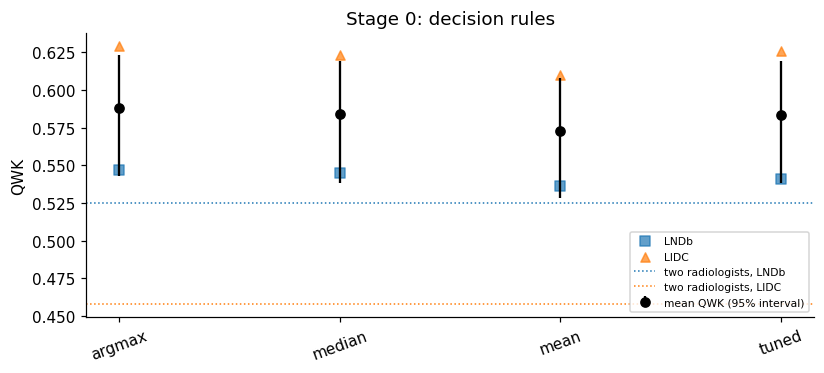

,mean_qwk,low,high,qwk_LNDb,qwk_LIDC,balanced_accuracy_LNDb,balanced_accuracy_LIDC,mae_LNDb,mae_LIDC,difference,difference_low,difference_high
config,,,,,,,,,,,,
rule_argmax,0.588,0.543,0.623,0.547,0.629,0.397,0.427,0.607,0.474,0.005,0.000,0.010
rule_median,0.584,0.538,0.619,0.545,0.623,0.392,0.418,0.602,0.487,0.000,-0.005,0.007
rule_mean,0.573,0.528,0.608,0.536,0.610,0.377,0.401,0.606,0.499,-0.010,-0.020,-0.001
rule_tuned,0.583,0.538,0.619,0.541,0.626,0.394,0.422,0.611,0.479,0.000,0.000,0.000


In [7]:
table = stage_table("rule_")
stage_figure(table, "Stage 0: decision rules")
table

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
  The three rules give close results: argmax 0.588, median 0.584 and mean 0.573. The mean is the only rule clearly worse than letting the inner folds choose (0.010 lower, interval from 0.020 to 0.001 lower). It pulls the predictions towards the middle ratings, which also lowers its balanced accuracy (0.377 in LNDb and 0.401 in LIDC IDRI, against 0.397 and 0.427 for argmax). The differences between argmax, median and the tuned rule are within the noise, so, as planned, the inner folds choose the rule from stage 1 on. They chose argmax in 11 of the 15 outer folds and the median in the other 4.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Stage 1: how to use LNDb and LIDC IDRI together
  </h3>
  <p>
  LNDb alone has 622 nodules and only 18 rated 5; LIDC IDRI adds 2615 nodules and 102 rated 5. The two datasets come from different scanners and different reading habits (47% of the LIDC IDRI nodules are rated 3, against 32% in LNDb), so pooling them can help or hurt. With the ordinal model, we compare:
  </p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;"><strong>each dataset alone</strong>, as a reference;</li>
    <li style="margin-bottom: 8px;"><strong>plain pooling</strong>, both datasets as they are;</li>
    <li style="margin-bottom: 8px;"><strong>a dataset indicator</strong>, one more column that lets the model shift its thresholds for LIDC IDRI;</li>
    <li style="margin-bottom: 8px;"><strong>ComBat harmonisation</strong> (Johnson et al., 2007; Orlhac et al., 2022) with LIDC IDRI as the reference batch, because it is the larger dataset: the LNDb features are moved onto the scale of LIDC IDRI, which stays unchanged (Zhang et al., 2018). The log diameter of the consensus region is kept as the biological covariate, so that size differences between the datasets are not removed as if they were scanner effects. The rating is not used as covariate, because the LNDb nodules that are adjusted are also validated, and their rating cannot be known when they are adjusted. ComBat is fitted on the training part of every fold only;</li>
    <li style="margin-bottom: 8px;"><strong>aggregation</strong>, one model per dataset and the average of their probabilities.</li>
  </ul>
</div>

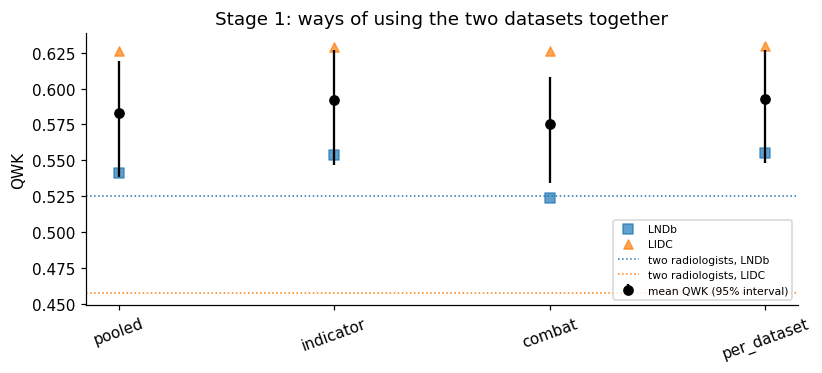

chosen: per_dataset


,mean_qwk,low,high,qwk_LNDb,qwk_LIDC,balanced_accuracy_LNDb,balanced_accuracy_LIDC,mae_LNDb,mae_LIDC,difference,difference_low,difference_high
config,,,,,,,,,,,,
pooling_LNDb_only,0.538,0.463,0.609,0.538,NaN,0.392,NaN,0.610,NaN,NaN,NaN,NaN
pooling_LIDC_only,0.635,0.598,0.668,NaN,0.635,NaN,0.435,NaN,0.475,NaN,NaN,NaN
pooling_pooled,0.583,0.538,0.619,0.541,0.626,0.394,0.422,0.611,0.479,0.000,0.000,0.000
pooling_indicator,0.592,0.547,0.627,0.554,0.629,0.402,0.428,0.594,0.473,0.009,0.002,0.016
pooling_combat,0.575,0.534,0.608,0.524,0.626,0.378,0.426,0.639,0.480,-0.008,-0.021,0.006
pooling_per_dataset,0.593,0.548,0.627,0.555,0.630,0.401,0.417,0.595,0.502,0.009,0.001,0.019


In [8]:
table = stage_table("pooling_")
together = table.drop(index=["pooling_LNDb_only", "pooling_LIDC_only"])
stage_figure(together, "Stage 1: ways of using the two datasets together")
print("chosen:", chosen["strategy"])
table

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
  Each dataset alone reaches 0.538 in LNDb and 0.635 in LIDC IDRI. Plain pooling reaches 0.583, with 0.541 in LNDb and 0.626 in LIDC IDRI. The dataset indicator (0.592) and aggregation (0.593) both beat plain pooling, with intervals of the difference that do not include zero (from 0.002 to 0.016 and from 0.001 to 0.019). ComBat is the only option below plain pooling (0.575), and the loss is all in LNDb (0.524). Moving the LNDb features onto the scale of LIDC IDRI also removes differences between the two cohorts that are not scanner effects and still carry information about the rating.
  </p>
  <p>
  By the rule fixed in advance, <strong>aggregation</strong> is kept: one model per dataset, with the average of their probabilities for every nodule. LNDb gains the most from it (0.555 against 0.538 alone), because the model trained on the larger LIDC IDRI adds information that the 622 LNDb nodules cannot provide alone. LIDC IDRI loses a little against its model alone (0.630 against 0.635), which the mean of the two datasets accepts in exchange for the gain in LNDb.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Stage 2: which model
  </h3>
  <p>
  With the chosen way of pooling, four models are compared: the ordinal logistic regression, a random forest, histogram gradient boosting and a support vector machine with an RBF kernel. The last three are nominal classifiers, which treat the ratings as unordered categories. Each is wrapped with the method of Frank and Hall (2001): four binary models answer "is the rating above 1, 2, 3, 4?", and the probabilities of the ratings follow from their differences. The order of the ratings is used, and the rare rating 5 is learnt together with the 4s in the question "above 4". The hyperparameters are chosen in the inner folds from small grids.
  </p>
</div>

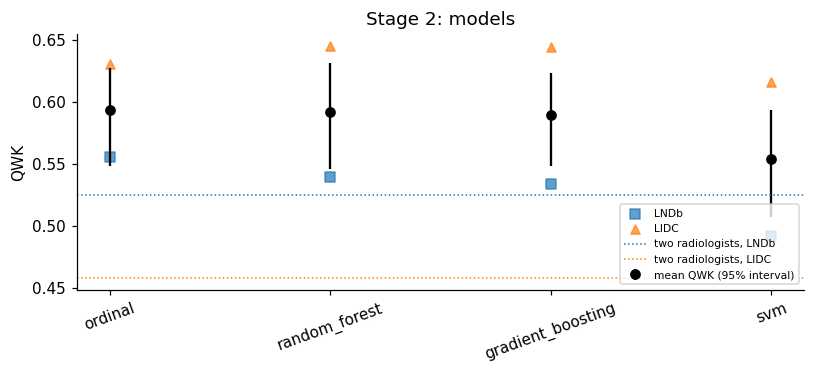

chosen: ordinal


,mean_qwk,low,high,qwk_LNDb,qwk_LIDC,balanced_accuracy_LNDb,balanced_accuracy_LIDC,mae_LNDb,mae_LIDC,difference,difference_low,difference_high
config,,,,,,,,,,,,
model_ordinal,0.593,0.548,0.627,0.555,0.630,0.401,0.417,0.595,0.502,0.000,0.000,0.000
model_random_forest,0.592,0.546,0.631,0.539,0.645,0.403,0.434,0.603,0.470,-0.000,-0.020,0.018
model_gradient_boosting,0.589,0.548,0.623,0.534,0.644,0.393,0.450,0.616,0.480,-0.003,-0.019,0.015
model_svm,0.554,0.507,0.593,0.492,0.616,0.371,0.425,0.633,0.475,-0.038,-0.066,-0.013


In [9]:
table = stage_table("model_")
stage_figure(table, "Stage 2: models")
print("chosen:", chosen["model"])
table

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
  No model beats the ordinal logistic regression (0.593). The random forest (0.592) and gradient boosting (0.589) are equal to it within the noise (intervals of the difference from 0.020 lower to 0.018 higher, and from 0.019 lower to 0.015 higher). They fit LIDC IDRI better (0.645 and 0.644 against 0.630) but LNDb worse (0.539 and 0.534 against 0.555): with only 622 nodules, the LNDb model of each pair is too small for flexible models. The support vector machine is clearly worse (0.038 lower, interval from 0.066 to 0.013 lower). The <strong>ordinal logistic regression</strong> is kept: it is the simplest model, its coefficients can be read directly, and the more flexible models do not pay for their complexity.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Stage 3: the training label
  </h3>
  <p>
  A nodule read by several radiologists has several ratings. We compare training on the mean rating of each nodule rounded half up (A) with training on every reading, each with the region and the rating of its radiologist and a weight of one divided by the number of readers, so that every nodule weighs the same (B; Raykar et al., 2010). The evaluation always uses label A.
  </p>
</div>

In [10]:
table = stage_table("label_")
print("chosen:", chosen["label"])
table

chosen: A


,mean_qwk,low,high,qwk_LNDb,qwk_LIDC,balanced_accuracy_LNDb,balanced_accuracy_LIDC,mae_LNDb,mae_LIDC,difference,difference_low,difference_high
config,,,,,,,,,,,,
label_A,0.593,0.548,0.627,0.555,0.630,0.401,0.417,0.595,0.502,0.000,0.000,0.000
label_B,0.593,0.547,0.630,0.550,0.637,0.411,0.432,0.597,0.518,0.001,-0.011,0.012


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
  Training on every reading (B) gives the same mean QWK as training on the mean label (A): 0.593 for both, with a difference of 0.001 (from 0.011 lower to 0.012 higher). B is slightly better in LIDC IDRI and slightly worse in LNDb. Since nothing is gained, the simpler <strong>label A</strong> is kept.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Stage 4: the 1 to 3 scale
  </h3>
  <p>
  The 1 to 3 scale (benign, indeterminate, suspicious) follows the decision a clinician takes. It can be obtained by grouping the predictions on the 1 to 5 scale, or by training directly on it. Its ceiling is lower than on the 1 to 5 scale, so the two scales are judged against their own ceilings.
  </p>
</div>

In [11]:
print("agreement between two radiologists on the 1 to 3 scale:", ceiling["QWK 1 to 3"].round(3).to_dict())
stage_table("scale3_")[["mean_qwk", "low", "high", "qwk_LNDb", "qwk_LIDC"] + difference]

agreement between two radiologists on the 1 to 3 scale: {'LIDC': 0.311, 'LNDb': 0.437}


,mean_qwk,low,high,qwk_LNDb,qwk_LIDC,difference,difference_low,difference_high
config,,,,,,,,
scale3_collapsed,0.495,0.451,0.536,0.448,0.543,NaN,NaN,NaN
scale3_direct,0.493,0.445,0.533,0.449,0.537,-0.002,-0.017,0.013


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
  On the 1 to 3 scale, grouping the 1 to 5 predictions reaches a mean QWK of 0.495 (from 0.451 to 0.536), with 0.448 in LNDb and 0.543 in LIDC IDRI. Training directly on the 1 to 3 scale gives 0.493, which is no better (difference 0.002 lower, from 0.017 lower to 0.013 higher). The grouped predictions are kept, so one model serves both scales. Both values are above the agreement between radiologists on this scale (0.437 and 0.311 for two radiologists, 0.42 and 0.40 for one radiologist against the others). The 1 to 3 scale has fewer levels, so each disagreement weighs more, which explains why every QWK is lower than on the 1 to 5 scale.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   The chosen configuration on new splits
  </h3>
  <p>
  Every stage chose among options on the same outer folds, which makes the reported score slightly optimistic. The chosen configuration is therefore evaluated again on three new seeds, which it never saw while being chosen.
  </p>
</div>

In [12]:
# The chosen configuration on the seeds used for choosing, and on three new seeds
chosen_key = f"label_{chosen['label']}"
confirmation = np.load(MODEL_RESULTS_DIR / "confirmation.npz", allow_pickle=True)
print("chosen:", chosen)
summary.loc[[chosen_key, "confirmation"], columns].round(3)

chosen: {'strategy': 'per_dataset', 'model': 'ordinal', 'label': 'A'}


,mean_qwk,low,high,qwk_LNDb,qwk_LIDC,balanced_accuracy_LNDb,balanced_accuracy_LIDC,mae_LNDb,mae_LIDC
config,,,,,,,,,
label_A,0.593,0.548,0.627,0.555,0.630,0.401,0.417,0.595,0.502
confirmation,0.590,0.545,0.624,0.554,0.625,0.395,0.421,0.600,0.501


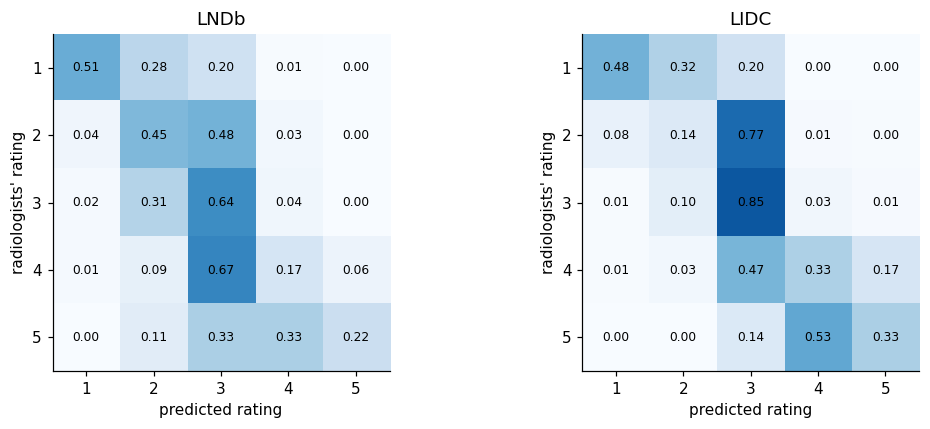

In [13]:
# Confusion matrices of the chosen configuration (first new seed), per dataset; each row sums to 1
decoded = confirmation["decoded"][0]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for axis, dataset in zip(axes, ("LNDb", "LIDC")):
    rows = (nodules["dataset"] == dataset).to_numpy()
    matrix = confusion_matrix(nodules["rating"][rows], decoded[rows], labels=range(1, 6), normalize="true")
    axis.imshow(matrix, cmap="Blues", vmin=0, vmax=1)
    for i in range(5):
        for j in range(5):
            axis.text(j, i, f"{matrix[i, j]:.2f}", ha="center", va="center", fontsize=8)
    axis.set(xticks=range(5), xticklabels=range(1, 6), yticks=range(5), yticklabels=range(1, 6),
             xlabel="predicted rating", ylabel="radiologists' rating", title=dataset)
plt.tight_layout()
plt.show()

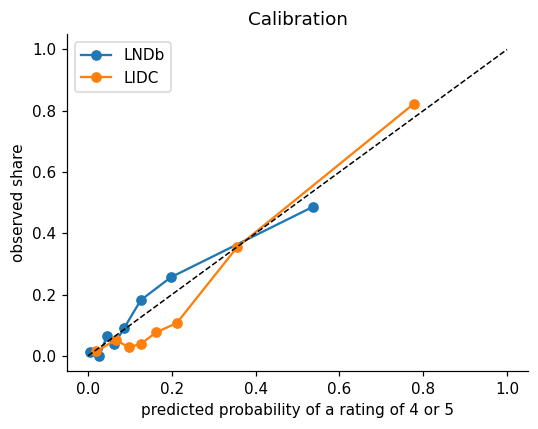

In [14]:
# Calibration: predicted probability of a rating of 4 or 5 against the observed share, in 8 groups of equal size
# (probabilities averaged over the three new seeds)
suspicious = confirmation["proba"][:, :, 3:].sum(axis=2).mean(axis=0)
is_suspicious = nodules["rating"].to_numpy() >= 4

fig, ax = plt.subplots(figsize=(5, 4))
for dataset in ("LNDb", "LIDC"):
    rows = (nodules["dataset"] == dataset).to_numpy()
    groups = pd.qcut(suspicious[rows], 8, duplicates="drop")
    predicted = pd.Series(suspicious[rows]).groupby(groups).mean()
    observed = pd.Series(is_suspicious[rows]).groupby(groups).mean()
    ax.plot(predicted, observed, marker="o", label=dataset)
ax.plot([0, 1], [0, 1], "k--", linewidth=1)          # perfect calibration
ax.set(xlabel="predicted probability of a rating of 4 or 5", ylabel="observed share", title="Calibration")
ax.legend()
plt.tight_layout()
plt.show()

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
  On three new seeds the chosen configuration reaches a mean QWK of 0.590 (from 0.545 to 0.624), with 0.554 in LNDb and 0.625 in LIDC IDRI, against 0.593 on the seeds used for choosing. The optimism caused by the choices is about 0.003, much smaller than the uncertainty of the estimate, so the reported performance can be trusted. On the 1 to 5 scale the model agrees with the label at least as well as one radiologist agrees with the others (0.527).
  </p>
  <p>
  The confusion matrices show the main weakness: the model is drawn towards rating 3, the most frequent one. In LIDC IDRI it predicts 3 for 77% of the nodules rated 2 and for 47% of those rated 4, and in LNDb for 67% of those rated 4. Large errors are rare: a nodule rated 1 is almost never predicted 4 or 5, and the reverse never happens. Calibration of the probability of a rating of 4 or 5 is reasonable in both datasets (mean predicted probability 0.14 against an observed share of 0.14 in LNDb, 0.23 against 0.19 in LIDC IDRI). The model is slightly too cautious for the most suspicious LIDC IDRI nodules and slightly too alarmed for the nodules of LIDC IDRI with a predicted probability between 0.1 and 0.2.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   What the model looks at
  </h3>
  <p>
  Permutation importance: on the outer folds of one seed, each feature is shuffled in turn inside the held out fold and the drop of the mean QWK is recorded (Molnar, 2022). A large drop means that the model relies on that feature. Features that are strongly correlated share their importance, which is why notebook 05 removed the most redundant ones.
  </p>
</div>

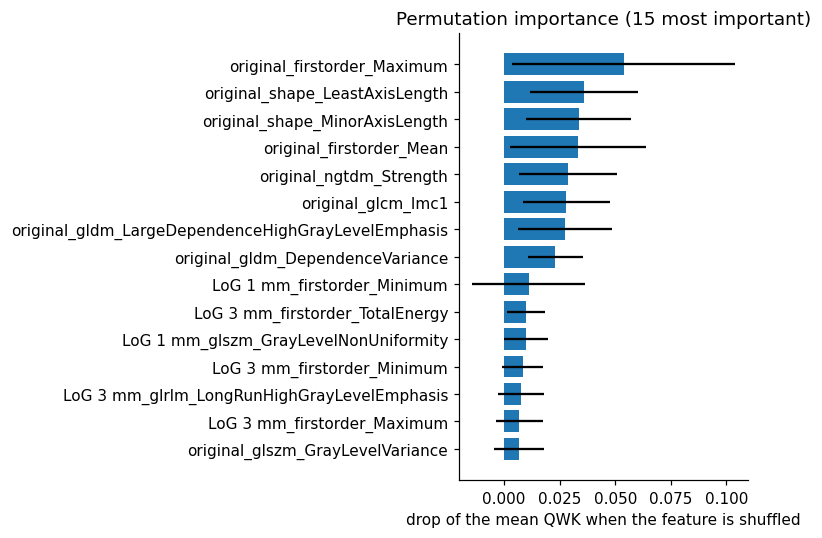

In [15]:
# The 15 most important features, with the standard deviation over folds and repeats
importance = pd.read_csv(MODEL_RESULTS_DIR / "permutation_importance.csv", index_col=0)
top = importance.head(15).iloc[::-1]
short_names = [name.replace("log-sigma-", "LoG ").replace("-0-mm-3D", " mm") for name in top.index]

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(short_names, top["importance"], xerr=top["sd"], color="tab:blue")
ax.set(xlabel="drop of the mean QWK when the feature is shuffled", title="Permutation importance (15 most important)")
plt.tight_layout()
plt.show()

In [16]:
# How the predicted probability of a rating of 4 or 5 grows with the diameter, against the observed share
size = pd.cut(nodules["roi_diameter_mm"], [0, 5, 8, 12, 20, 100],
              labels=["under 5 mm", "5 to 8", "8 to 12", "12 to 20", "20 mm or more"])
pd.DataFrame({
    "nodules": size.value_counts(sort=False),
    "observed share of 4 and 5": pd.Series(is_suspicious).groupby(size, observed=False).mean(),
    "predicted probability": pd.Series(suspicious).groupby(size, observed=False).mean(),
}).round(2)

,nodules,observed share of 4 and 5,predicted probability
roi_diameter_mm,,,
under 5 mm,1266,0.03,0.07
5 to 8,1201,0.09,0.15
8 to 12,414,0.36,0.34
12 to 20,264,0.77,0.69
20 mm or more,92,0.80,0.88


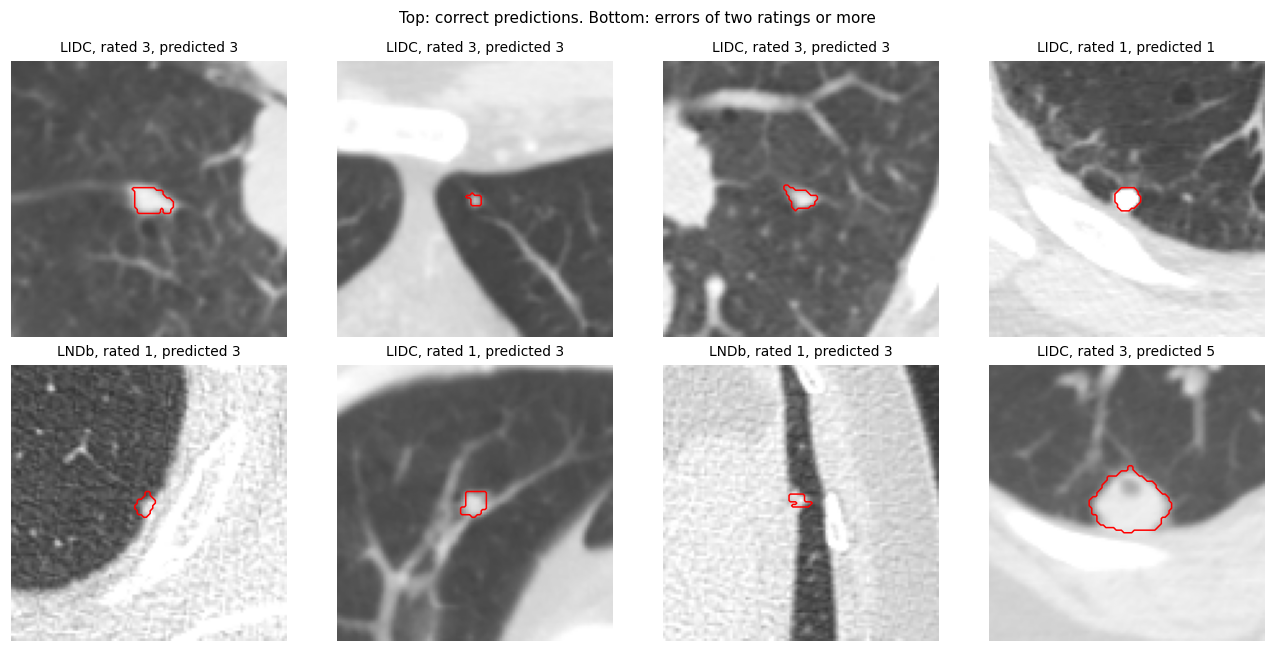

In [17]:
# Central axial slice with the consensus contour: four correct predictions and four errors of two ratings or more
manifest = pd.concat([pd.read_csv(LNDB_MANIFEST_FILE), pd.read_csv(LIDC_MANIFEST_FILE)])
file_of = dict(zip(manifest["patch_id"], manifest["file"]))
error = np.abs(decoded - nodules["rating"].to_numpy())
rng = np.random.default_rng(0)
correct = rng.choice(np.flatnonzero(error == 0), 4, replace=False)
wrong = rng.choice(np.flatnonzero(error >= 2), 4, replace=False)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for axis, row in zip(axes.ravel(), list(correct) + list(wrong)):
    nodule = nodules.iloc[row]
    patch = np.load(PATCHES_DIR / file_of[nodule["patch_id"]])
    rois = np.load(ROI_DIR / f"{nodule['patch_id']}.npz")
    axis.imshow(patch[CENTRE_INDEX], cmap="gray", vmin=-1350, vmax=150)      # lung window
    axis.contour(rois["consensus"][CENTRE_INDEX], levels=[0.5], colors="red", linewidths=1)
    axis.set_title(f"{nodule['dataset']}, rated {nodule['rating']}, predicted {decoded[row]}", fontsize=9)
    axis.axis("off")
fig.suptitle("Top: correct predictions. Bottom: errors of two ratings or more", fontsize=10)
plt.tight_layout()
plt.show()

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
  The model relies on the features that radiologists use. The most important are the brightest value inside the nodule (first order maximum) and its mean density, which separate solid nodules from ground glass ones; the two shortest axes of the nodule (least and minor axis length), which measure size; and several texture features (NGTDM strength, GLCM informational correlation, two GLDM features) that describe how heterogeneous the nodule is. Shuffling any of these lowers the mean QWK by 0.02 to 0.05. Only 37 of the 63 features lower the QWK at all when shuffled, so many features carry information that others already give.
  </p>
  <p>
  The predicted probability of a rating of 4 or 5 follows the observed share across sizes: 0.07 against 0.03 below 5 mm, 0.15 against 0.09 from 5 to 8 mm, 0.34 against 0.36 from 8 to 12 mm, 0.69 against 0.77 from 12 to 20 mm and 0.88 against 0.80 from 20 mm. The model reproduces the strong role of size in the ratings, in line with the size thresholds of the Fleischner guidelines (MacMahon et al., 2017), without being a size model only, as the baselines showed. The examples of large errors are small nodules rated 1 but predicted 3, often next to vessels or the pleura, and a large solid nodule rated 3 but predicted 5: in both cases size and density point one way and the radiologists decided the other way, probably from context that the patch does not show.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Conclusions and limits
  </h3>
  <p>
  The chosen configuration is an <strong>ordinal logistic regression on 63 robust PyRadiomics features, one model per dataset with their probabilities averaged, trained on the mean rating and with the decision rule chosen in the inner folds</strong>. On new splits it reaches a mean QWK of 0.590 (95% interval from 0.545 to 0.624) on the 1 to 5 scale, 0.555 in LNDb and 0.625 in LIDC IDRI, and 0.495 on the 1 to 3 scale. It agrees with the label at least as well as one radiologist agrees with the others, and adds 0.21 to the diameter alone. More flexible models, ComBat harmonisation and training on single readings did not help.
  </p>
  <p>
  Limits:
  </p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">The label is a subjective rating of malignancy by radiologists, not a diagnosis confirmed by biopsy or follow up, so the model learns how radiologists rate nodules, not whether a nodule is cancer.</li>
    <li style="margin-bottom: 8px;">LNDb is small (622 nodules, 18 rated 5), so its scores have wide intervals, and the rare ratings 4 and 5 are often predicted as 3.</li>
    <li style="margin-bottom: 8px;">All results come from cross validation on the training data of the two datasets. They are not an evaluation on a separate test set or on another hospital.</li>
    <li style="margin-bottom: 8px;">The penalty of the ordinal model was most often chosen at the largest value of its grid (100), so a larger value might be slightly better.</li>
    <li style="margin-bottom: 8px;">The features describe only the region drawn by the radiologists. Context outside the nodule, which radiologists also look at, is not used.</li>
  </ul>
  <p>
  </p>
</div>